# 결정 규칙

이 규칙을 쓰기 전에는 그룹을 나누지 않은 값만 봤다. 행 수, 결측, 중복, 전체 리텐션, 전체 플레이 수 분포, 감지 가능한 최소 차이(MDE)다.

## 1. 질문과 행동

**질문.** 첫 관문을 레벨 30에서 40으로 옮기면 7일 리텐션이 옮길 가치가 있을 만큼 오르는가.

**기본값은 "그대로 둔다"이다.** 옮기는 데 비용이 들고 리텐션 외의 이득(매출 등)은 이 데이터로 알 수 없다. 그래서 리텐션이 1%p 이상 오르는 것이 확실해야만 옮긴다.

차이는 `gate_40 − gate_30`으로 계산한다.

| 7일 리텐션 차이의 95% 신뢰구간 | 권고 | 서술 |
|---|---|---|
| 전체가 +1%p보다 위 | 40으로 옮긴다 | 옮길 가치가 있을 만큼 오른다 |
| 전체가 0보다 위지만 +1%p에 못 미치거나 걸침 | 그대로 둔다 | 오르지만 옮길 만큼 큰지 확실하지 않다 |
| 0을 포함 | 그대로 둔다 | 오른다는 증거를 찾지 못했다 |
| 전체가 0보다 아래 | 그대로 둔다 | 옮기면 리텐션이 떨어진다 |

이 권고는 리텐션 기준이다. 매출은 이 데이터로 판단할 수 없다.

## 2. 주 지표

**`retention_7`** (설치 후 정확히 7일째에 플레이했는가. "7일 안에"가 아니다.)

처치가 지표에 닿아야 한다. 전체 사용자의 63%는 14일 동안 30판도 하지 않아 레벨 30 관문을 만나지 않았고 레벨 30~40에 가려면 7일 동안 하루 평균 4~6레벨을 올려야 하므로 1일째에는 관문에 도달한 사용자가 거의 없다고 가정한다. 이 가정은 레벨 도달 시점 데이터가 없어 확인할 수 없다.

## 3. 보조 지표

결정에는 쓰지 않고 주 지표 결과를 이해하는 데 쓴다.

- **`retention_1`**: 점검용. 위 가정이 맞다면 두 그룹에서 차이가 없어야 한다. 차이가 나면 가정이 틀렸거나 배정에 문제가 있다는 신호로 본다.
- **`sum_gamerounds`**: 리텐션이 변할 때 플레이 양도 함께 변했는지 본다.

## 4. 검정 방식

- 양측 검정. 관문을 옮기면 리텐션이 오를 수도 내릴 수도 있다.
- 주 지표: 유의수준 0.05. 두 비율 z검정과 차이의 95% 신뢰구간.
- 보조 지표 2개: 본페로니 보정으로 각각 유의수준 0.025.

## 5. 판단 기준

**1%p.** 사업 맥락이 없으므로 가정이다.

- 뜻: 옮길 가치가 있는 최소 상승폭.
- 근거: 7일째에 돌아오는 사용자는 100명 중 18.6명이다. 1%p는 그중 약 1명, 5% 정도다. 이만큼은 늘어야 옮기는 비용을 감수할 만하다고 가정한다.
- MDE(0.73%p)보다 크므로 이 실험으로 가를 수 있는 크기다.

차이의 크기를 서술할 때도 같은 기준을 쓴다.

| 신뢰구간의 위치 | 크기에 대한 서술 |
|---|---|
| 전체가 −1%p와 +1%p 사이 | 차이가 있어도 작다 |
| 전체가 그 바깥 | 차이가 크다 |
| 1%p 선을 걸침 | 크기는 불확실하다 |

## 6. 표본 비율 점검 (SRM)

- 카이제곱 적합도 검정으로 그룹 인원이 50:50에 맞는지 본다.
- 기준: p값이 0.01보다 작으면 SRM이 의심된다고 본다.
- 걸리면: 분석은 계속하되 결론의 확신을 낮추고 한계에 적는다. 공개 데이터라 배정 과정을 조사할 수 없기 때문이다.
- 통과하더라도 배정 과정을 확인할 수 없다는 점을 한계에 적는다.

## 7. 데이터 처리

- 사용자를 걸러내지 않는다. 90,189명 전원을 분석한다. 플레이 수는 관문 위치의 영향을 받는 값이라, 그것으로 사용자를 빼면 두 그룹을 비교할 수 없게 된다.
- 극단값 사용자도 빼지 않는다. 플레이 수는 평균 대신 중앙값으로 비교한다.


## 결정 규칙 전에 본 것

아래 셀은 모두 그룹(`version`)을 나누지 않고 계산한다.

### 데이터 불러오기

In [2]:
import numpy as np
import pandas as pd
from scipy.stats import norm

df = pd.read_csv('data/cookie_cats.csv')
print(df.shape)
df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


### 결측과 중복

In [3]:
print("결측:", df.isna().sum().sum())
print("중복 userid:", df["userid"].duplicated().sum())

결측: 0
중복 userid: 0


### 전체 리텐션

In [4]:
ret1_all = df["retention_1"].mean()
ret7_all = df["retention_7"].mean()

print(f"전체 1일 리텐션: {ret1_all:.1%}")
print(f"전체 7일 리텐션: {ret7_all:.1%}")

전체 1일 리텐션: 44.5%
전체 7일 리텐션: 18.6%


### 감지 가능한 최소 차이 (MDE)

유의수준 5%(양측), 검정력 80% 기준. 그룹별 실제 인원은 아직 보지 않았으므로 반반이라고 가정한다.

In [5]:
n_per_group = len(df) / 2


def mde(p, n):
    se = np.sqrt(2 * p * (1 - p) / n)
    return (1.96 + 0.84) * se


print(f"MDE (1일 리텐션): {mde(ret1_all, n_per_group):.2%}p")
print(f"MDE (7일 리텐션): {mde(ret7_all, n_per_group):.2%}p")

MDE (1일 리텐션): 0.93%p
MDE (7일 리텐션): 0.73%p


### 전체 플레이 수 분포

In [6]:
rounds = df["sum_gamerounds"]

print(f"평균: {rounds.mean():.1f}")
print(f"중앙값: {rounds.median():.0f}")
print(f"99% 분위수: {rounds.quantile(0.99):.0f}")
print(f"최댓값: {rounds.max()}")
print(f"0판 사용자: {(rounds == 0).mean():.1%}")
print(f"30판 미만 사용자: {(rounds < 30).mean():.1%}")

평균: 51.9
중앙값: 16
99% 분위수: 493
최댓값: 49854
0판 사용자: 4.4%
30판 미만 사용자: 63.1%


## 표본 비율 점검 (SRM)
효과를 보기 전에 50:50으로 배정됐는지 확인한다. 제대로 배정되지 않았다면 실험의 결과에 대한 신뢰도가 떨어진다.

In [7]:
from scipy.stats import chisquare

counts = df['version'].value_counts()
print(counts)

expected = [len(df) / 2, len(df) / 2]
stat, p_srm = chisquare(counts, f_exp=expected)

print(f'카이제곱 통계량: {stat:.2f}')
print(f'p값: {p_srm:.4f}')

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64
카이제곱 통계량: 6.90
p값: 0.0086


두 그룹의 인원은 `gate_40` 45,489명, `gate_30` 44,700명으로 789명 차이가 난다. 비율로는 50.44% 대 49.56%다. 배정이 정말 50:50이었다면 이 정도 이상으로 어긋날 확률(p값)은 0.0086이다. 
결정 규칙에서 정한 기준 0.01보다 작으므로 SRM이 의심된다고 판정한다. 다만 기준에 가까운 값이다. 비율로는 작은 어긋남이지만 표본이 9만 명이라 우연의 흔들림이 작아서 검정에 걸렸다.

결정 규칙대로 분석은 계속하되 결론의 확신을 낮추고 한계에 적는다. 공개 데이터라 배정 과정을 확인할 수 없어 어긋남의 원인은 알 수 없다.

## 데이터 점검
플레이 수와 리텐션이 정의대로 기록됐는지 본다

In [8]:
print(df.sort_values('sum_gamerounds', ascending=False).head(5))

print(pd.crosstab(df['retention_1'], df['retention_7']))

print('0판인데 1일 리텐션 True:', ((rounds == 0) & df['retention_1']).sum())
print('0판인데 7일 리텐션 True:', ((rounds == 0) & df['retention_7']).sum())

        userid  version  sum_gamerounds  retention_1  retention_7
57702  6390605  gate_30           49854        False         True
7912    871500  gate_30            2961         True         True
29417  3271615  gate_40            2640         True        False
43671  4832608  gate_30            2438         True         True
48188  5346171  gate_40            2294         True         True
retention_7  False  True 
retention_1              
False        46437   3599
True         26971  13182
0판인데 1일 리텐션 True: 87
0판인데 7일 리텐션 True: 29


`sum_gamerounds`의 최댓값은 49,854판이고 2위는 2,961판으로 약 17배 차이가 난다. 이 사용자 한 명이 자기 그룹(`gate_30`)의 평균 플레이 수를 약 1.1판 끌어올린다. 그래도 이 사용자를 빼지 않고, 플레이 수는 평균 대신 중앙값으로 비교한다.

교차표를 보면 1일째에는 왔지만 7일째에는 오지 않은 사용자가 26,971명이다. `retention_7`이 "7일 안에 돌아왔는가"였다면 이 칸은 0명이어야 한다. 따라서 `retention_7`은 그날까지 돌아왔는지가 아니라 해당 날짜에 돌아왔는지를 기록한 값이다.

한 판도 하지 않았는데 리텐션이 True인 사용자가 1일 기준 87명, 7일 기준 29명 있다. 컬럼 설명은 "플레이했는가"인데 실제로는 접속 기준으로 기록됐을 수 있다. 이유는 확인할 수 없다. 전체의 0.1% 수준이라 결과에 미치는 영향은 작고, 이 사용자들도 빼지 않는다.

플레이 수로 사용자를 걸러내지 않는다. 플레이 수는 관문 위치의 영향을 받는 값이다. 예를 들어 30판 이상인 사용자만 남기면, 관문에 막혀 그만두는 사용자가 한쪽 그룹에서만 더 많이 빠질 수 있다. 그러면 남은 두 그룹의 구성이 달라져서 차이가 나도 관문 때문인지 가를 수 없다. 또 판 수는 레벨이 아니라서 30판 이상이라고 관문을 만난 사용자가 골라지지도 않는다.


## 주 지표 효과 추정

결정 규칙에서 정한 주 지표인 7일 리텐션의 그룹 간 차이와 95% 신뢰구간을 구하고 두 비율 z검정을 한다. 먼저 공식대로 직접 계산한 뒤 라이브러리 함수로 같은 값이 나오는지 확인한다.

In [9]:
g = df.groupby('version')['retention_7'].agg(['sum', 'count', 'mean'])
print(g)

n30, n40 = g.loc['gate_30', 'count'], g.loc['gate_40', 'count']
p30, p40 = g.loc['gate_30', 'mean'], g.loc['gate_40', 'mean']

diff = p40 - p30
se = np.sqrt(p30 * (1 - p30) / n30 + p40 * (1 - p40) / n40)
z = diff / se
p_value = 2 * norm.sf(abs(z))
ci_low, ci_high = diff - 1.96 * se, diff + 1.96 * se

print(f'차이: {diff:.2%}p')
print(f'z값: {z:.2f}, p값: {p_value:.4f}')
print(f'95% 신뢰구간: [{ci_low:.2%}p, {ci_high:.2%}p]')

          sum  count      mean
version                       
gate_30  8502  44700  0.190201
gate_40  8279  45489  0.182000
차이: -0.82%p
z값: -3.16, p값: 0.0016
95% 신뢰구간: [-1.33%p, -0.31%p]


라이브러리 함수로 같은 값이 나오는지 확인한다.

In [10]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

x30, x40 = g.loc['gate_30', 'sum'], g.loc['gate_40', 'sum']

z_lib, p_lib = proportions_ztest([x40, x30], [n40, n30])
low_lib, high_lib = confint_proportions_2indep(x40, n40, x30, n30, method='wald', compare='diff')

print(f'z값: {z_lib:.2f}, p값: {p_lib:.4f}')
print(f'95% 신뢰구간: [{low_lib:.2%}p, {high_lib:.2%}p]')

z값: -3.16, p값: 0.0016
95% 신뢰구간: [-1.33%p, -0.31%p]


관문을 40으로 옮기면 7일 리텐션이 19.02%에서 18.20%로 0.82%p 떨어진다. z값은 -3.16으로 차이가 표준오차의 3.16배다. 관문 위치에 효과가 없다면 이 정도 이상의 차이가 나올 확률(p값)은 0.0016이므로 유의수준 0.05에서 유의하다. 95% 신뢰구간은 [-1.33%p, -0.31%p]로 0을 포함하지 않는다.

결정 규칙은 1%p 이상 올라야 옮기는 것이었으므로 그대로 둔다. 신뢰구간이 -1%p 선을 걸치므로 하락의 크기가 1%p를 넘는지는 불확실하다.

## 부트스트랩으로 재확인
주 지표의 신뢰구간을 공식이 아닌 다른 방법으로 다시 구해, 결과가 계산 방법에 기대고 있지 않은지 확인한다. 그룹별로 같은 인원을 복원 추출해 리텐션 차이를 구하는 일을 1만 번 반복하고, 그 값들의 가운데 95% 범위를 신뢰구간으로 삼는다.

In [12]:
rng = np.random.default_rng(42)

r30 = df.loc[df['version'] == 'gate_30', 'retention_7'].to_numpy()
r40 = df.loc[df['version'] == 'gate_40', 'retention_7'].to_numpy()

boot_diffs = []
for _ in range(10_000):
    s30 = rng.choice(r30, size=len(r30), replace=True)
    s40 = rng.choice(r40, size=len(r40), replace=True)
    boot_diffs.append(s40.mean() - s30.mean())
boot_diffs = np.array(boot_diffs)

print(boot_diffs[:5])
print(f'부트스트랩 표준오차: {boot_diffs.std():.2%}p')

low_b, high_b = np.percentile(boot_diffs, [2.5, 97.5])
print(f'부트스트랩 95% 신뢰구간: [{low_b:.2%}p, {high_b:.2%}p]')

[-0.01140402 -0.00853182 -0.00586305 -0.00547277 -0.00639647]
부트스트랩 표준오차: 0.26%p
부트스트랩 95% 신뢰구간: [-1.34%p, -0.32%p]


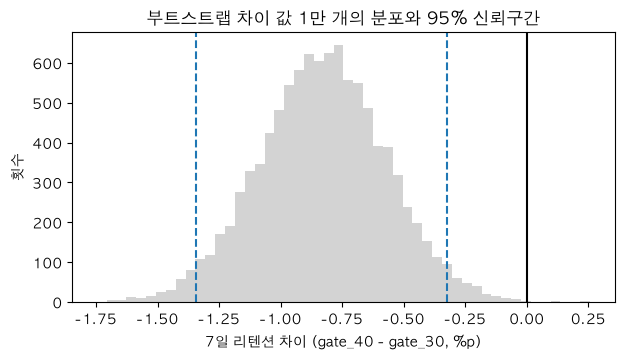

In [16]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(boot_diffs * 100, bins=50, color="lightgray")
ax.axvline(low_b * 100, color='tab:blue', linestyle='--')
ax.axvline(high_b * 100, color="tab:blue", linestyle="--")
ax.axvline(0, color='black')
ax.set_xlabel('7일 리텐션 차이 (gate_40 - gate_30, %p)')
ax.set_ylabel('횟수')
ax.set_title('부트스트랩 차이 값 1만 개의 분포와 95% 신뢰구간')
plt.show()


부트스트랩으로 구한 표준오차는 0.26%p, 95% 신뢰구간은 [-1.34%p, -0.32%p]다. 공식으로 구한 표준오차 0.26%p, 신뢰구간 [-1.33%p, -0.31%p]와 거의 같다. 0.01%p의 차이는 무작위로 다시 뽑는 데서 생긴다. 차이 값 1만 개의 분포는 종 모양이어서 z검정이 전제한 모양과도 맞는다. 주 지표의 결과는 계산 방법을 바꿔도 달라지지 않는다.

이 분포는 추정값이 표본에 따라 흔들리는 정도를 보여줄 뿐이고, 진짜 차이가 어디에 있을 확률을 뜻하지 않는다. 그래서 "`gate_30`이 더 나을 확률"로 쓰지 않고 차이의 신뢰구간으로 서술한다.

## 보조 지표
보조 지표는 권고에 쓰지 않고 주 지표 결과를 이해하는 맥락으로 본다. 지표를 여러 개 검정하면 그중 하나가 우연히 유의하게 나올 확률이 커지므로, 본페로니 보정으로 유의수준을 0.05 ÷ 2 = 0.025로 낮춰서 본다.

In [21]:
alpha_secondary = 0.05 / 2
z_crit = norm.ppf(1 - alpha_secondary / 2)
print(f"보조 지표의 유의수준: {alpha_secondary}, 기준 z값: {z_crit:.2f}")

g1 = df.groupby("version")["retention_1"].agg(["sum", "count", "mean"])
print(g1)

x30_1, x40_1 = g1.loc["gate_30", "sum"], g1.loc["gate_40", "sum"]
diff1 = g1.loc["gate_40", "mean"] - g1.loc["gate_30", "mean"]

z1, p1 = proportions_ztest([x40_1, x30_1], [n40, n30])
low1, high1 = confint_proportions_2indep(
    x40_1, n40, x30_1, n30, method="wald", compare="diff", alpha=alpha_secondary
)

print(f"차이: {diff1:.2%}p")
print(f"z값: {z1:.2f}, p값: {p1:.4f}")
print(f"97.5% 신뢰구간: [{low1:.2%}p, {high1:.2%}p]")

보조 지표의 유의수준: 0.025, 기준 z값: 2.24
           sum  count      mean
version                        
gate_30  20034  44700  0.448188
gate_40  20119  45489  0.442283
차이: -0.59%p
z값: -1.78, p값: 0.0744
97.5% 신뢰구간: [-1.33%p, 0.15%p]


In [22]:
summary = df.groupby("version")["sum_gamerounds"].agg(["mean", "median"])
print(summary)

gr30 = df.loc[df["version"] == "gate_30", "sum_gamerounds"].to_numpy()
gr40 = df.loc[df["version"] == "gate_40", "sum_gamerounds"].to_numpy()

rng = np.random.default_rng(42)
boot_med = []
for _ in range(10_000):
    b30 = rng.choice(gr30, size=len(gr30), replace=True)
    b40 = rng.choice(gr40, size=len(gr40), replace=True)
    boot_med.append(np.median(b40) - np.median(b30))
boot_med = np.array(boot_med)

med_diff = summary.loc["gate_40", "median"] - summary.loc["gate_30", "median"]
low_m, high_m = np.percentile(boot_med, [1.25, 98.75])

print(f"중앙값 차이: {med_diff:.1f}판")
print(f"97.5% 신뢰구간: [{low_m:.1f}판, {high_m:.1f}판]")
print(pd.Series(boot_med).value_counts().sort_index())


              mean  median
version                   
gate_30  52.456264    17.0
gate_40  51.298776    16.0
중앙값 차이: -1.0판
97.5% 신뢰구간: [-1.0판, 0.0판]
-1.0    9324
-0.5       7
 0.0     662
 1.0       7
Name: count, dtype: int64


1일 리텐션은 `gate_30` 44.82%, `gate_40` 44.23%로 0.59%p 차이가 난다. p값은 0.0744로 유의수준 0.025보다 크다. 관문 위치가 1일 리텐션과 아무 관계가 없는 세상에서도 100번에 7번 정도는 일어날 수 있는 차이여서 귀무가설을 뒤집을 근거가 없다. 97.5% 신뢰구간 [-1.33%p, +0.15%p]도 0을 포함한다. "1일째에는 관문에 도달한 사용자가 거의 없다"는 가정과 어긋나는 결과는 아니다. 다만 신뢰구간이 넓어서 1%p가 넘는 하락도 배제하지 못하므로 가정이 확인됐다고 말할 수는 없다.

플레이 수의 중앙값은 `gate_30` 17판, `gate_40` 16판으로 1판 차이가 난다. 평균은 `gate_30`이 1.16판 높지만, `gate_30`에 있는 49,854판 사용자 한 명이 그룹 평균을 1.12판 끌어올린 것이어서 평균 차이의 대부분은 이 한 명에게서 나왔다. 그래서 중앙값으로 비교한다. 중앙값 차이의 97.5% 신뢰구간은 [-1판, 0판]으로 0을 포함하므로 유의하다고 볼 수 없다. 판 수가 정수라 중앙값 비교의 눈금은 1판 단위이고 그보다 작은 차이는 볼 수 없다.

두 보조 지표 모두 관측된 방향은 주 지표와 같지만(`gate_40`이 낮음) 유의하지 않으며, 권고를 바꾸지 않는다.